# Electron tomography workflow (rg-tomo, Python)

Run the cells from top to bottom; some sections are alternatives or optional, so skip the ones you do not need.

In [1]:
import sys
TOOLBOX = r"C:\Users\rgirod\Data\rg-tomo2026-python"   # folder containing the rgtomo package
if TOOLBOX not in sys.path:
    sys.path.insert(0, TOOLBOX)

import numpy as np
import matplotlib.pyplot as plt
import rgtomo as rgt
%matplotlib inline

print("rgtomo", rgt.__version__, "| ASTRA CUDA available:", rgt.has_cuda())

rgtomo 0.1.0 | ASTRA CUDA available: True


---
## Preprocessing
### Loading data
Loading has three options:
- `'fast'` assumes one file `TomoX.emi` and a corresponding `TomoX.log`, otherwise provide an angle file
  (a multi-frame Velox `.emd` is also accepted)
- `'manual'` assumes one folder and one `.emi`/`.ser` or `.emd` per angle
- `'tif'` assumes one `series.tif` and one `angle.csv` (or a folder of `.tif` files with the angles in their names)

In [ ]:
fname = r"\\ematbyname\all\emattitan\RobinG\20240206_RG_Titan1_BinamKin2_PT\Grid1E8_PTS60\Tomo1"
fangles = None          # angles file, optional, None if unused
ftype = 'manual'      # 'fast', 'manual', 'tif'

series_raw = rgt.uniloader(fname, fangles, ftype)

print(series_raw)
rgt.slice_viewer(series_raw)

Reading EMI files:   0%|          | 0/50 [00:00<?, ?it/s]

Loaded 50 projections with 0.194 nm pixel size
TiltSeries(50 projections of 1024 x 1024 px, pixel size 0.5 nm, angles -72.0..74.9 deg, dtype float32)


### Preprocessing and initial alignment
**Binning.** Think about your required resolution, a rule of thumb is to have at least 4-5 pixels for the
smallest features to be analyzed. It is not advised to keep more than this for size and noise considerations.

**Alignment.** For isolated particles, it works best to select one angle to which all projections will be
aligned. For slab-like cases, alignment to the previous image typically works better.

**Denoising.** A simple gaussian is often sufficient here.

In [4]:
# Parameters
rescale_factor = 0.5          # (float): Factor of the new pixel size
slice_to_align_to = 20    # (int): Projection index (0-based) or None to align to neighbor
window = False              # (bool): adds a hamming window, can help if the ROI is not well isolated
edge = 2                    # (int): gaussian sigma after sobel filtering. if 0: no edge filter
iterations = 3              # (int): Iterations for x-correlation, typically 1-3
slab_like = False           # (bool):  if slab-like will stretch following 1/cos
y_range = None              # (start, end) or None: rows used to find the shifts: 
sigma_gauss_filter = 1      # (float): Denoising with gaussian filter, 0 for none

# Run code
series = series_raw.copy()

# normalize each projection -> not always a correct assumption!
series.data = rgt.normalize_intensities(series.data)

if rescale_factor < 1:
    series = rgt.imresize_stack(series, rescale_factor)
    print(f"new pixel size: {series.pixel_size:.3f} nm")

series.data = rgt.gaussfilter_slice(series.data, sigma_gauss_filter)

stack = None
if iterations > 0:
    series.data, _, _, stack = rgt.align_stack_xcorr(series, slice_to_align_to, window, edge,
                                                     iterations, slab_like, 1, y_range)
series.data = rgt.rescale(series.data)

new pixel size: 0.388 nm
xcorr alignment, iteration 1
Aligning without windowing...
Applying an edge detector...
Finding shifts via cross-correlation...


xcorr:   0%|          | 0/50 [00:00<?, ?it/s]

xcorr alignment, iteration 2
Aligning without windowing...
Applying an edge detector...
Finding shifts via cross-correlation...


xcorr:   0%|          | 0/50 [00:00<?, ?it/s]

xcorr alignment, iteration 3
Aligning without windowing...
Applying an edge detector...
Finding shifts via cross-correlation...


xcorr:   0%|          | 0/50 [00:00<?, ?it/s]

In [5]:
# Check alignment: aligned series (top) and the filtered images used to find the shifts (bottom)
rgt.slice_viewer(series.data if stack is None else np.concatenate([series.data, rgt.rescale(stack)], axis=2))

## Crop and rotate
The tilt series must be rotated to be vertical. Here we only correct for the fact that the scan direction has
typically a 90° difference between the Osiris and the Titans.
**/!\ rotate by 1x90° only for the Titans, 0 for the Osiris.**

Draw the ROI on the projection (or use the sliders), then run the next cell to crop.

In [6]:
rotate = 1   # rotation of n times 90°

series_test = series.copy()
series_test.data = rgt.rot90_stack(series_test.data, rotate)
crop_gui = rgt.crop_stack_gui(series_test)
crop_gui

In [7]:
series_test = crop_gui.result()
print("ROI (x0, y0, width, height):", crop_gui.rect, "->", series_test)

ROI (x0, y0, width, height): (166, 91, 302, 406) -> TiltSeries(50 projections of 406 x 302 px, pixel size 0.388 nm, angles -72.0..74.9 deg, dtype float32)


## Fast tomo processing
In fast tomo datasets, degraded images need to be removed. The next 4 cells offer different ways to do so.\
If you are working with a "clean" dataset already, skip ahead to the final processing section

### Remove bad images - self-consistency
This script will compute a reconstruction and reproject it, then compare the original and simulated tilt-series
with SSIM. Only the original projections that best match with the reprojections will be kept.

In [ ]:
series_retained = rgt.generate_clean_tilt_series(series_test, plot=True)
rgt.slice_viewer(series_retained)

### Remove bad images - Manual
Indices are 0-based, as shown by the viewer slider. Run this cell only once (indices refer to `series_test`
before the removal).

In [ ]:
exclude_list = [26]

series_test = rgt.select_images(series_test, exclude_list)
rgt.slice_viewer(series_test)

Alternatively, review the projections one by one (Keep / Remove):

In [15]:
select_gui = rgt.select_images_gui(series_test)
select_gui

In [16]:
series_test = select_gui.result()
print("removed:", select_gui.excluded, "->", series_test)

removed: [] -> TiltSeries(52 projections of 114 x 85 px, pixel size 1 nm, angles -77.0..75.9 deg, dtype float32)


---
## Final processing
### Final background removal and second alignment
**Background removal** (optional): the script will fit a background function, subtract it, and remove parts
that are below an intensity threshold. Decrease `BGSUBTRACT_THRESHOLD` to remove less.

**Slab-like** parameters when working with continuous geometries (not isolated particles): only use if you
already know the tilt axis to be more or less vertical. Will apply a stretching function only for alignment
that compensates the fact that new areas are entering the ROI at high angles.
**/!\ this assumes the tilt axis is vertical, it may be needed to iterate a few times between this alignment
and the tilt-axis one.**

As in `tomography.m`, the cleaned series is used for `'fast'` data, otherwise `series_test`.

In [11]:
'''Background params'''
remove_background = True        # (bool)
BGSUBTRACT_THRESHOLD = 0.5      # factor of otsu graythresh to keep, higher removes more, default 0.5

'''Alignment params'''
slice_to_align_to = 20      # (int): Projection index (0-based) or None to align to neighbor
window = False              # (bool): adds a hamming window, can help if the ROI is not well isolated
edge = 0                    # (int): gaussian sigma after sobel filtering. if 0: no edge filter
iterations = 3              # (int): Iterations for x-correlation, typically 1-3
slab_like = False           # (bool):  if slab-like will stretch following 1/cos
y_range = None              # (start, end) or None: rows used to find the shifts: 
sigma_gauss_filter = 1      # (float): Denoising with gaussian filter, 0 for none

'''RUN'''
series_final = (series_retained if ftype == 'fast' else series_test).copy()

if remove_background:
    series_final.data = rgt.background_subtract(series_final.data, BGSUBTRACT_THRESHOLD)
    series_final.data = rgt.normalize_intensities(series_final.data)   # norm each proj to mean 1 std 1
series_final.data = rgt.rescale(series_final.data)
if iterations > 0:
    series_final.data, _, _, stack = rgt.align_stack_xcorr(series_final, slice_to_align_to, window, edge,
                                                           iterations, slab_like, 1, y_range)

rgt.slice_viewer(series_final.data if stack is None else np.concatenate([series_final.data, rgt.rescale(stack)], axis=2))

Removing background:   0%|          | 0/50 [00:00<?, ?it/s]

xcorr alignment, iteration 1
Aligning without windowing...
Aligning with regular images...
Finding shifts via cross-correlation...


xcorr:   0%|          | 0/50 [00:00<?, ?it/s]

xcorr alignment, iteration 2
Aligning without windowing...
Aligning with regular images...
Finding shifts via cross-correlation...


xcorr:   0%|          | 0/50 [00:00<?, ?it/s]

xcorr alignment, iteration 3
Aligning without windowing...
Aligning with regular images...
Finding shifts via cross-correlation...


xcorr:   0%|          | 0/50 [00:00<?, ?it/s]

## Align tilt axis
Three slices are reconstructed: shift/rotate the tilt axis (red line) and press *Preview* until the arcs of a
misaligned axis disappear. Run the next cell to apply. (This tool can be used at any stage, e.g. again after the
self-consistency refinements.)

In [12]:
tilt_gui = rgt.align_tilt_axis_gui(series_final)
tilt_gui

In [13]:
series_final = tilt_gui.result()
print(f"tilt axis translation {tilt_gui.translation} px, rotation {tilt_gui.rotation} deg")

tilt axis translation 2.0 px, rotation 0.0 deg


## Refinement with vertical mass fluctuation / common line
This script projects each image on the Y-axis. If the tilt axis is well aligned, these curves should be equal
and the Y shifts can be determined by minimizing this error.

VMF refinement:   0%|          | 0/3 [00:00<?, ?it/s]

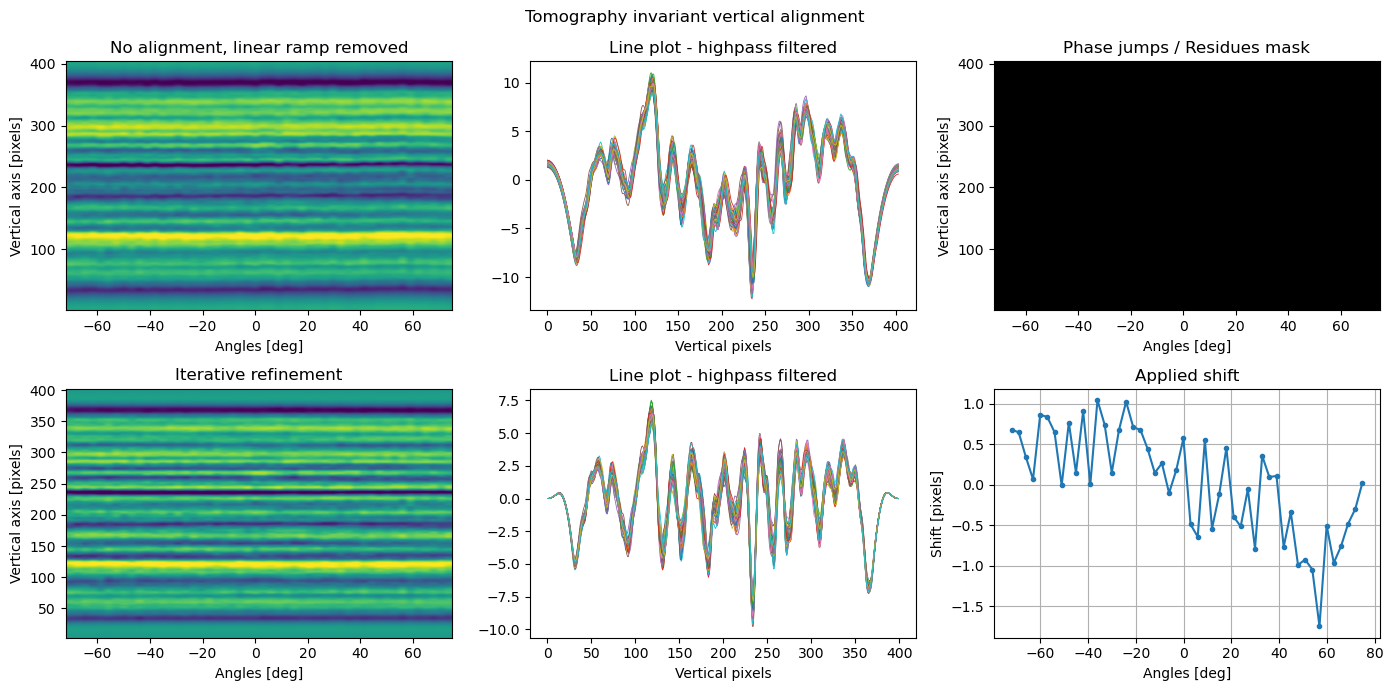

In [15]:
high_pass_filter = 0.01        # band pass filter, lower = more filtering, 0.005-0.01 needed for STEM

series_final_vmf = rgt.csaxs_vmf(series_final, high_pass_filter)
series_final_vmf.data = rgt.rescale(series_final_vmf.data)

rgt.slice_viewer(series_final_vmf)

### Finalize the alignment manually if required
Green: image *i*, magenta: image *i*+1. Shift with the arrow buttons, or the keyboard with the mouse over the
image (arrows, A/D for previous/next, PageUp/PageDown to change the step). Run the next cell to apply.

In [19]:
manual_gui = rgt.align_stack_manual_gui(series_final_vmf)
manual_gui

In [20]:
series_final_vmf = manual_gui.result()

## Cupping correction (optional, for large particles)
Increase the correction strength until the reconstructed slice (EM/SIRT) has no darker core.

In [21]:
cupping_gui = rgt.cupping_correction_gui(series_final_vmf)
cupping_gui

In [22]:
series_final = cupping_gui.result()
series_final.data = rgt.remove_bkg_median(series_final.data)

## Reconstruction

In [23]:
alg = 'em'   # 'em', 'sirt', 'fbp'
it = 25        # iterations, 25 for EM, up to 50-100 for SIRT

series_rec = series_final                          # tilt series to reconstruct
result = rgt.reconstruct(series_rec, alg, it, True, 30)  # apodization, 30 px padding
rgt.orthoslice_viewer(result)

Performing reconstruction using EM algorithm...


EM reconstruction:   0%|          | 0/406 [00:00<?, ?it/s]

## Post-processing
### Align and post process
Simple filtering in 3D + alignment of the major axis of reconstruction using the first principal component.
If the reconstruction is not a rod, leave the PCA line commented.

In [24]:
gaussian_sigma = 1            # std of the gaussian kernel, in vx
median_kernel = (1, 1, 1)     # size of the median kernel

result_processed = result.astype(np.float32)
result_processed = rgt.gaussian_filter_3d(result_processed, gaussian_sigma)
result_processed = rgt.median_filter_3d(result_processed, median_kernel)
result_processed = rgt.align_z_pca(result_processed, (1, 99))  # lower and upper percentile thresholds for outliers

rgt.orthoslice_viewer(result_processed)

## Export
### Save reconstruction
An automated naming is proposed, which assumes that the input file or folder was named
`\\yourTitan\sample\TomoX.ser` and exports files to `\\save_folder\sample\sample_PX_alg.rec` where P stands for
"particle", X is the acquisition number, alg is the algorithm used for reconstruction.

Otherwise, you can provide a root and all files will be exported to `\\save_folder\root_alg.rec`
(the default root below differs from the MATLAB one so the MATLAB results in the same folder are not overwritten).

In [37]:
save_folder = r"C:\Users\rgirod\Data\rg-tomo2026-python\data"
save_all = 2              # 0: only tomo rec, 1: tomo and tomo processed, 2: tomo, aligned tilt series, csv, slices if exist
from_root = 'Rec_py'  # Option to override automated naming, None for the automated naming

# Naming and folder management
rec_name = rgt.get_series_names(fname, save_folder, from_root)
if 'alg' in globals():
    rec_name = f"{rec_name}{alg}{it}"
print("saving rec:", rec_name)

# Saving
if 'result' in globals():
    rgt.write_rec(result, rec_name + '.rec', series_rec.pixel_size)
if save_all > 0 and 'result_processed' in globals():
    rgt.write_rec(result_processed, rec_name + '_processed.rec', series_rec.pixel_size)
if save_all > 1:
    rgt.write_tiff(series_rec.data, rec_name + '_tiltSeries.tiff', series_rec.pixel_size)
    rgt.write_angles_csv(series_rec.angles, rec_name + '_tiltAngles.csv')

saving rec: C:\Users\rgirod\Data\rg-tomo2026-python\data\Rec_py_em25
